In [51]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

os.makedirs("../reports/figures", exist_ok=True)

In [ ]:
files = os.listdir("../data/raw")

for file in files:
    print(file)

In [ ]:
demo = pd.read_sas("../data/raw/DEMO_L.xpt", encoding="infer")
dpq = pd.read_sas("../data/raw/DPQ_L.xpt", encoding="infer")
bmx = pd.read_sas("../data/raw/BMX_L.xpt", encoding="infer")
bpxo = pd.read_sas("../data/raw/BPXO_L.xpt", encoding="infer")

In [7]:
print("DEMO:", demo.shape)
print("DPQ:", dpq.shape)
print("BMX:", bmx.shape)
print("BPXO:", bpxo.shape)

DEMO: (11933, 27)
DPQ: (6337, 11)
BMX: (8860, 22)
BPXO: (7801, 12)


In [5]:
print(demo["SEQN"].head())
print(dpq["SEQN"].head())
print(bmx["SEQN"].head())
print(bpxo["SEQN"].head())

0    130378.0
1    130379.0
2    130380.0
3    130381.0
4    130382.0
Name: SEQN, dtype: float64
0    130378.0
1    130379.0
2    130380.0
3    130386.0
4    130387.0
Name: SEQN, dtype: float64
0    130378.0
1    130379.0
2    130380.0
3    130381.0
4    130382.0
Name: SEQN, dtype: float64
0    130378.0
1    130379.0
2    130380.0
3    130386.0
4    130387.0
Name: SEQN, dtype: float64


In [6]:
print("DEMO:", demo["SEQN"].nunique())
print("DPQ:", dpq["SEQN"].nunique())
print("BMX:", bmx["SEQN"].nunique())
print("BPXO:", bpxo["SEQN"].nunique())

DEMO: 11933
DPQ: 6337
BMX: 8860
BPXO: 7801


In [8]:
common_ids = set(demo["SEQN"]) & set(dpq["SEQN"]) & set(bmx["SEQN"]) & set(bpxo["SEQN"])

print("People present in all four files:", len(common_ids))

People present in all four files: 6337


<div dir="rtl" style="text-align: right;">
بررسی اولیه ساختار داده‌ها

چهار فایل اصلی <span dir="ltr">NHANES 2021–2023</span> بارگذاری شدند. تعداد رکوردهای هر فایل به شرح زیر است:
فایل	تعداد رکورد
DEMO_L	11,933

DPQ_L	6,337

BMX_L	8,860

BPXO_L	7,801

شناسه <span dir="ltr">SEQN</span> در هر چهار فایل منحصربه‌فرد است و شناسه تکراری مشاهده نشد.

اشتراک شناسه‌ها نشان داد تمام ۶٬۳۳۷ فرد موجود در فایل <span dir="ltr">DPQ</span>، در سه فایل دیگر نیز رکورد دارند.

محدودیت این نتیجه: وجود رکورد در یک فایل به معنی معتبر یا کامل بودن تمام متغیرهای آن نیست. بررسی مقادیر گمشده و اعتبار اندازه‌گیری‌ها هنوز انجام نشده است.
</div>

In [9]:
print(dpq.isnull().sum())

SEQN         0
DPQ010     818
DPQ020     819
DPQ030     821
DPQ040     823
DPQ050     824
DPQ060     827
DPQ070     829
DPQ080     829
DPQ090     831
DPQ100    2170
dtype: int64


In [11]:
print(demo.columns.tolist())

['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR']


In [12]:
print("DEMO")
print(demo[[
    "RIDAGEYR", "RIAGENDR", "RIDRETH3",
    "DMDEDUC2", "INDFMPIR",
    "WTMEC2YR", "SDMVSTRA", "SDMVPSU"
]].isnull().sum())

print("\nDPQ")
print(dpq[[
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]].isnull().sum())

print("\nBMX")
print(bmx[["BMXBMI", "BMXWAIST"]].isnull().sum())

print("\nBPXO")
print(bpxo[[
    "BPXOSY1", "BPXODI1",
    "BPXOSY2", "BPXODI2",
    "BPXOSY3", "BPXODI3"
]].isnull().sum())

DEMO
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
DMDEDUC2    4139
INDFMPIR    2041
WTMEC2YR       0
SDMVSTRA       0
SDMVPSU        0
dtype: int64

DPQ
DPQ010    818
DPQ020    819
DPQ030    821
DPQ040    823
DPQ050    824
DPQ060    827
DPQ070    829
DPQ080    829
DPQ090    831
dtype: int64

BMX
BMXBMI      389
BMXWAIST    670
dtype: int64

BPXO
BPXOSY1    284
BPXODI1    284
BPXOSY2    296
BPXODI2    296
BPXOSY3    321
BPXODI3    321
dtype: int64


In [13]:
adult_ids = demo.loc[demo["RIDAGEYR"] >= 20, "SEQN"]

demo_adults = demo[demo["RIDAGEYR"] >= 20]
dpq_adults = dpq[dpq["SEQN"].isin(adult_ids)]
bmx_adults = bmx[bmx["SEQN"].isin(adult_ids)]
bpxo_adults = bpxo[bpxo["SEQN"].isin(adult_ids)]

print("Number of adults:", len(adult_ids))

print("\nDEMO")
print(demo_adults[[
    "RIDAGEYR", "RIAGENDR", "RIDRETH3",
    "DMDEDUC2", "INDFMPIR", "WTMEC2YR"
]].isnull().sum())

print("\nDPQ")
print(dpq_adults[[
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]].isnull().sum())

print("\nBMX")
print(bmx_adults[["BMXBMI", "BMXWAIST"]].isnull().sum())

print("\nBPXO")
print(bpxo_adults[[
    "BPXOSY1", "BPXODI1",
    "BPXOSY2", "BPXODI2",
    "BPXOSY3", "BPXODI3"
]].isnull().sum())

Number of adults: 7809

DEMO
RIDAGEYR       0
RIAGENDR       0
RIDRETH3       0
DMDEDUC2      15
INDFMPIR    1320
WTMEC2YR       0
dtype: int64

DPQ
DPQ010    791
DPQ020    792
DPQ030    794
DPQ040    796
DPQ050    797
DPQ060    799
DPQ070    801
DPQ080    801
DPQ090    803
dtype: int64

BMX
BMXBMI       94
BMXWAIST    302
dtype: int64

BPXO
BPXOSY1    201
BPXODI1    201
BPXOSY2    208
BPXODI2    208
BPXOSY3    221
BPXODI3    221
dtype: int64


In [14]:
phq_items = [
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]

print("Code 7 (Refused):")
print((dpq_adults[phq_items] == 7).sum())

print("\nCode 9 (Don't know):")
print((dpq_adults[phq_items] == 9).sum())

Code 7 (Refused):
DPQ010    5
DPQ020    3
DPQ030    3
DPQ040    3
DPQ050    0
DPQ060    3
DPQ070    2
DPQ080    4
DPQ090    0
dtype: int64

Code 9 (Don't know):
DPQ010    16
DPQ020     7
DPQ030     4
DPQ040     5
DPQ050     3
DPQ060     2
DPQ070     1
DPQ080     8
DPQ090     5
dtype: int64


In [15]:
print("DEMO adults:", demo_adults["SEQN"].nunique())
print("DPQ adults:", dpq_adults["SEQN"].nunique())
print("BMX adults:", bmx_adults["SEQN"].nunique())
print("BPXO adults:", bpxo_adults["SEQN"].nunique())

common_adult_ids = (
    set(demo_adults["SEQN"])
    & set(dpq_adults["SEQN"])
    & set(bmx_adults["SEQN"])
    & set(bpxo_adults["SEQN"])
)

print("\nAdults present in all four files:", len(common_adult_ids))

DEMO adults: 7809
DPQ adults: 6064
BMX adults: 6064
BPXO adults: 6064

Adults present in all four files: 6064


In [16]:
analysis_data = demo_adults.merge(
    dpq_adults,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

analysis_data = analysis_data.merge(
    bmx_adults,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

analysis_data = analysis_data.merge(
    bpxo_adults,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

print("Merged dataset shape:", analysis_data.shape)
print("Unique participants:", analysis_data["SEQN"].nunique())

Merged dataset shape: (6064, 69)
Unique participants: 6064


In [17]:
variables = [
    "RIDAGEYR", "RIAGENDR", "RIDRETH3",
    "DMDEDUC2", "INDFMPIR", "WTMEC2YR",
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090",
    "BMXBMI", "BMXWAIST",
    "BPXOSY1", "BPXODI1",
    "BPXOSY2", "BPXODI2",
    "BPXOSY3", "BPXODI3"
]

missing_counts = analysis_data[variables].isnull().sum()

print(missing_counts)

RIDAGEYR      0
RIAGENDR      0
RIDRETH3      0
DMDEDUC2      0
INDFMPIR    792
WTMEC2YR      0
DPQ010      791
DPQ020      792
DPQ030      794
DPQ040      796
DPQ050      797
DPQ060      799
DPQ070      801
DPQ080      801
DPQ090      803
BMXBMI       94
BMXWAIST    302
BPXOSY1     201
BPXODI1     201
BPXOSY2     208
BPXODI2     208
BPXOSY3     221
BPXODI3     221
dtype: int64


In [19]:
phq_items = [
    "DPQ010", "DPQ020", "DPQ030",
    "DPQ040", "DPQ050", "DPQ060",
    "DPQ070", "DPQ080", "DPQ090"
]

valid_phq = (
    (analysis_data[phq_items] >= 0) &
    (analysis_data[phq_items] <= 3)
).all(axis=1)

print("Total participants:", len(analysis_data))
print("Participants with 9 valid answers:", valid_phq.sum())
print("Participants without a complete PHQ-9:", (~valid_phq).sum())

Total participants: 6064
Participants with 9 valid answers: 5210
Participants without a complete PHQ-9: 854


In [20]:
analysis_data["PHQ9"] = (
    analysis_data[phq_items]
    .sum(axis=1)
    .where(valid_phq)
)

print("PHQ-9 scores:")
print(analysis_data["PHQ9"].describe())

print("\nMinimum score:", analysis_data["PHQ9"].min())
print("Maximum score:", analysis_data["PHQ9"].max())
print("Number of valid scores:", analysis_data["PHQ9"].count())

PHQ-9 scores:
count    5.210000e+03
mean     4.039923e+00
std      4.682504e+00
min      4.857845e-78
25%      1.000000e+00
50%      2.000000e+00
75%      6.000000e+00
max      2.600000e+01
Name: PHQ9, dtype: float64

Minimum score: 4.857844812240625e-78
Maximum score: 26.0
Number of valid scores: 5210


In [21]:
analysis_data["PHQ9"] = analysis_data["PHQ9"].round()

print(analysis_data["PHQ9"].describe())

count    5210.000000
mean        4.039923
std         4.682504
min         0.000000
25%         1.000000
50%         2.000000
75%         6.000000
max        26.000000
Name: PHQ9, dtype: float64


In [22]:
systolic_readings = ["BPXOSY1", "BPXOSY2", "BPXOSY3"]
diastolic_readings = ["BPXODI1", "BPXODI2", "BPXODI3"]

analysis_data["Mean_Systolic"] = analysis_data[systolic_readings].mean(axis=1)
analysis_data["Mean_Diastolic"] = analysis_data[diastolic_readings].mean(axis=1)

print(analysis_data[["Mean_Systolic", "Mean_Diastolic"]].describe())

       Mean_Systolic  Mean_Diastolic
count    5863.000000     5863.000000
mean      122.929672       74.736568
std        18.080907       10.998172
min        70.000000       34.000000
25%       110.666667       67.333333
50%       120.333333       74.000000
75%       132.666667       81.333333
max       232.333333      139.000000


In [23]:
print("Number of available systolic readings per person:")
print(analysis_data[systolic_readings].notnull().sum(axis=1).value_counts().sort_index())

print("\nNumber of available diastolic readings per person:")
print(analysis_data[diastolic_readings].notnull().sum(axis=1).value_counts().sort_index())

print("\nIndividual blood pressure readings:")
print(analysis_data[systolic_readings + diastolic_readings].describe())

Number of available systolic readings per person:
0     201
1       6
2      15
3    5842
Name: count, dtype: int64

Number of available diastolic readings per person:
0     201
1       6
2      15
3    5842
Name: count, dtype: int64

Individual blood pressure readings:
           BPXOSY1      BPXOSY2      BPXOSY3      BPXODI1      BPXODI2  \
count  5863.000000  5856.000000  5843.000000  5863.000000  5856.000000   
mean    123.073512   122.935622   122.727708    75.307351    74.632514   
std      18.538614    18.481272    18.378173    11.375422    11.302631   
min      75.000000    65.000000    62.000000    37.000000    32.000000   
25%     110.000000   110.000000   110.000000    68.000000    67.000000   
50%     121.000000   120.000000   120.000000    75.000000    74.000000   
75%     133.000000   133.000000   132.000000    82.000000    81.000000   
max     232.000000   233.000000   232.000000   142.000000   139.000000   

           BPXODI3  
count  5843.000000  
mean     74.265275  

In [25]:
# تعداد اندازه‌گیری‌های موجود برای هر فرد
bp_count = analysis_data[systolic_readings].notna().sum(axis=1)

# افرادی که هر سه اندازه‌گیری را دارند
complete_bp = bp_count == 3

print("Participants with at least one reading:", bp_count.gt(0).sum())
print("Participants with all three readings:", complete_bp.sum())
print("Participants with incomplete readings:", ((bp_count > 0) & (~complete_bp)).sum())

print("\nComparison of mean blood pressure:")

print("All available readings:")
print(analysis_data[["Mean_Systolic", "Mean_Diastolic"]].mean())

print("\nOnly participants with all three readings:")
print(analysis_data.loc[complete_bp, ["Mean_Systolic", "Mean_Diastolic"]].mean())

Participants with at least one reading: 5863
Participants with all three readings: 5842
Participants with incomplete readings: 21

Comparison of mean blood pressure:
All available readings:
Mean_Systolic     122.929672
Mean_Diastolic     74.736568
dtype: float64

Only participants with all three readings:
Mean_Systolic     122.895527
Mean_Diastolic     74.734166
dtype: float64


<div dir="rtl" style="text-align: right;">
### بررسی اندازه‌گیری‌های فشار خون و ساخت شاخص میانگین

در فایل BPXO برای هر شرکت‌کننده حداکثر سه اندازه‌گیری فشار خون سیستولیک و سه اندازه‌گیری دیاستولیک ثبت شده است.

در مجموعه‌داده ادغام‌شده شامل ۶۰۶۴ بزرگسال:

- ۵۸۴۲ نفر هر سه اندازه‌گیری را دارند.
- ۱۵ نفر دو اندازه‌گیری دارند.
- ۶ نفر فقط یک اندازه‌گیری دارند.
- ۲۰۱ نفر هیچ اندازه‌گیری‌ای ندارند.

برای ساخت شاخص فشار خون هر فرد، میانگین اندازه‌گیری‌های موجود محاسبه شده است. مقادیر خالی در محاسبه میانگین نادیده گرفته می‌شوند؛ بنابراین افرادی که فقط یک یا دو اندازه‌گیری دارند نیز می‌توانند در تحلیل‌های مربوط به فشار خون وارد شوند. برای ۲۰۱ نفری که هیچ اندازه‌گیری معتبری ندارند، شاخص میانگین خالی باقی می‌ماند.

در نتیجه، برای هر دو شاخص میانگین فشار سیستولیک و دیاستولیک ۵۸۶۳ مقدار قابل استفاده وجود دارد.

این تصمیم به معنی معتبر دانستن خودکار تمام مقادیر ثبت‌شده نیست. مقادیر بسیار بالا یا پایین در مرحله کنترل دامنه و مقادیر غیرعادی جداگانه بررسی خواهند شد.
</div>


In [26]:
print("Missing BMI values:", analysis_data["BMXBMI"].isna().sum())

print("\nBMI summary:")
print(analysis_data["BMXBMI"].describe())

print("\nBMI values equal to zero or below:")
print((analysis_data["BMXBMI"] <= 0).sum())

Missing BMI values: 94

BMI summary:
count    5970.000000
mean       29.827035
std         7.358598
min        11.100000
25%        24.700000
50%        28.500000
75%        33.600000
max        74.800000
Name: BMXBMI, dtype: float64

BMI values equal to zero or below:
0


In [27]:
Q1 = analysis_data["BMXBMI"].quantile(0.25)
Q3 = analysis_data["BMXBMI"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = analysis_data[
    (analysis_data["BMXBMI"] < lower_bound) |
    (analysis_data["BMXBMI"] > upper_bound)
]

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))
print("\nPotential outlier BMI values:")
print(outliers["BMXBMI"].sort_values().to_list())

IQR: 8.900000000000002
Lower bound: 11.349999999999996
Upper bound: 46.95
Number of potential outliers: 173

Potential outlier BMI values:
[11.1, 47.0, 47.1, 47.2, 47.2, 47.2, 47.3, 47.5, 47.5, 47.5, 47.6, 47.7, 47.7, 47.8, 47.8, 47.9, 47.9, 47.9, 47.9, 47.9, 47.9, 47.9, 48.0, 48.0, 48.1, 48.1, 48.1, 48.1, 48.2, 48.2, 48.3, 48.3, 48.4, 48.5, 48.5, 48.5, 48.5, 48.5, 48.5, 48.6, 48.6, 48.7, 48.7, 48.7, 48.8, 48.8, 48.9, 48.9, 48.9, 49.0, 49.0, 49.1, 49.2, 49.3, 49.4, 49.4, 49.4, 49.5, 49.6, 49.7, 49.7, 49.8, 49.8, 49.8, 49.9, 49.9, 50.0, 50.0, 50.0, 50.1, 50.1, 50.2, 50.2, 50.2, 50.3, 50.3, 50.4, 50.5, 50.5, 50.5, 50.6, 50.7, 50.7, 50.7, 50.8, 51.1, 51.2, 51.2, 51.3, 51.6, 51.6, 51.7, 51.7, 51.7, 51.8, 51.8, 51.8, 51.9, 51.9, 52.0, 52.0, 52.3, 52.4, 52.5, 52.5, 52.5, 52.5, 52.6, 52.6, 52.6, 52.6, 52.7, 52.8, 53.0, 53.0, 53.0, 53.1, 53.2, 53.7, 53.9, 54.1, 54.2, 54.4, 54.5, 54.6, 55.0, 55.1, 55.1, 55.7, 55.9, 56.1, 56.3, 56.3, 56.4, 56.4, 56.7, 56.9, 56.9, 57.0, 57.2, 57.4, 57.5, 57.6, 58

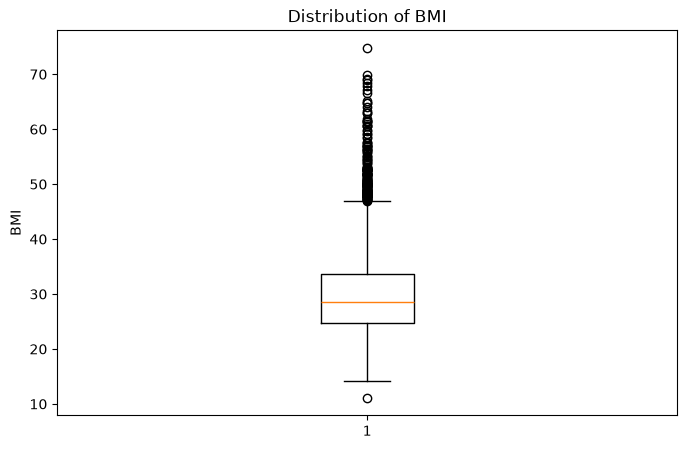

In [52]:
plt.figure(figsize=(8, 5))

plt.boxplot(analysis_data["BMXBMI"].dropna())

plt.ylabel("BMI")
plt.title("Distribution of BMI")

plt.savefig(
    "../reports/figures/bmi_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<div dir="rtl" style="text-align: right;">
### بررسی کیفیت داده‌های BMI

متغیر BMI مستقیماً از ستون BMXBMI در فایل BMX_L دریافت شده است. از 6064 شرکت‌کننده در مجموعه داده ادغام‌شده، 94 نفر (حدود 1.5 درصد) مقدار BMI گمشده دارند.

میانگین BMI برابر 29.83 و میانه آن برابر 28.5 است. برای شناسایی مقادیر پرت بالقوه از روش IQR استفاده شد.

با Q1 برابر 24.7 و Q3 برابر 33.6، مقدار IQR برابر 8.9 و مرزهای تشخیص مقادیر پرت برابر 11.35 و 46.95 به دست آمد. در مجموع 173 مشاهده خارج از این مرزها قرار گرفتند.

بررسی Boxplot نشان داد که بیشتر مقادیر پرت در سمت بالای توزیع قرار دارند. این مشاهدات صرفاً به دلیل پرت بودن حذف نشدند، زیرا ممکن است مقادیر واقعی BMI باشند و حذف آن‌ها می‌تواند بر بررسی ارتباط شاخص‌های چاقی با علائم افسردگی اثر بگذارد.
</div>

In [32]:
print("Missing waist circumference values:",
      analysis_data["BMXWAIST"].isna().sum())

print("\nWaist circumference summary:")
print(analysis_data["BMXWAIST"].describe())

print("\nValues equal to zero or below:")
print((analysis_data["BMXWAIST"] <= 0).sum())

Missing waist circumference values: 302

Waist circumference summary:
count    5762.000000
mean      101.087817
std        16.898478
min        60.000000
25%        88.900000
50%        99.500000
75%       111.400000
max       187.000000
Name: BMXWAIST, dtype: float64

Values equal to zero or below:
0


In [33]:
Q1_waist = analysis_data["BMXWAIST"].quantile(0.25)
Q3_waist = analysis_data["BMXWAIST"].quantile(0.75)

IQR_waist = Q3_waist - Q1_waist

lower_waist = Q1_waist - 1.5 * IQR_waist
upper_waist = Q3_waist + 1.5 * IQR_waist

waist_outliers = analysis_data[
    (analysis_data["BMXWAIST"] < lower_waist) |
    (analysis_data["BMXWAIST"] > upper_waist)
]

print("IQR:", IQR_waist)
print("Lower bound:", lower_waist)
print("Upper bound:", upper_waist)
print("Number of potential outliers:", len(waist_outliers))

print("\nPotential outlier values:")
print(waist_outliers["BMXWAIST"].sort_values().to_list())

IQR: 22.5
Lower bound: 55.150000000000006
Upper bound: 145.15
Number of potential outliers: 79

Potential outlier values:
[145.3, 145.4, 145.6, 145.9, 146.0, 146.2, 146.4, 146.4, 146.5, 146.5, 146.6, 146.7, 146.8, 146.8, 147.2, 147.3, 147.4, 147.8, 148.0, 148.2, 148.3, 148.4, 148.5, 148.7, 149.0, 149.0, 149.1, 149.2, 149.3, 149.3, 149.4, 149.5, 149.8, 150.2, 150.3, 150.5, 150.5, 151.1, 151.2, 151.2, 151.7, 151.8, 151.9, 152.2, 152.7, 152.9, 153.3, 153.4, 154.5, 154.6, 154.7, 155.0, 155.5, 155.5, 155.7, 155.8, 156.0, 156.7, 157.1, 157.4, 157.7, 158.1, 158.3, 158.6, 158.7, 159.6, 160.1, 163.2, 163.3, 164.6, 165.2, 168.0, 169.0, 170.0, 171.0, 171.5, 177.2, 177.7, 187.0]


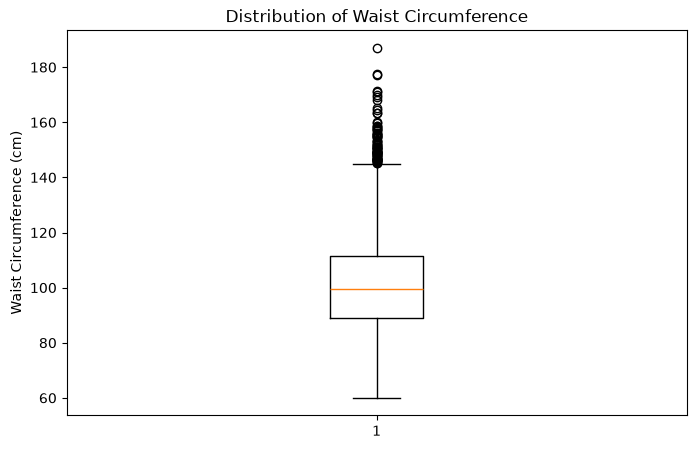

In [53]:
plt.figure(figsize=(8, 5))

plt.boxplot(analysis_data["BMXWAIST"].dropna())

plt.ylabel("Waist Circumference (cm)")
plt.title("Distribution of Waist Circumference")

plt.savefig(
    "../reports/figures/waist_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<div dir="rtl" style="text-align: right">
### بررسی کیفیت داده‌های دور کمر

متغیر دور کمر (BMXWAIST) مستقیماً از فایل BMX_L دریافت شده و واحد آن سانتی‌متر است.

از 6064 شرکت‌کننده در مجموعه داده ادغام‌شده، 302 نفر (حدود 5 درصد) مقدار دور کمر گمشده دارند.

میانگین دور کمر 101.09 و میانه آن 99.5 سانتی‌متر است.

با استفاده از روش IQR، مقدار Q1 برابر 88.9، مقدار Q3 برابر 111.4 و مقدار IQR برابر 22.5 محاسبه شد. مرزهای تشخیص مقادیر پرت 55.15 و 145.15 سانتی‌متر به دست آمدند.

در مجموع 79 مشاهده (حدود 1.4 درصد از مقادیر معتبر) خارج از این مرزها قرار گرفتند. تمام این مشاهدات در سمت بالای توزیع بودند.

این مقادیر صرفاً به دلیل پرت بودن حذف نشدند؛ زیرا ممکن است اندازه‌گیری‌های واقعی مربوط به افراد دارای دور کمر بسیار بالا باشند.
</div>

In [35]:
# Systolic blood pressure
Q1_sys = analysis_data["Mean_Systolic"].quantile(0.25)
Q3_sys = analysis_data["Mean_Systolic"].quantile(0.75)

IQR_sys = Q3_sys - Q1_sys

lower_sys = Q1_sys - 1.5 * IQR_sys
upper_sys = Q3_sys + 1.5 * IQR_sys

sys_outliers = analysis_data[
    (analysis_data["Mean_Systolic"] < lower_sys) |
    (analysis_data["Mean_Systolic"] > upper_sys)
]

# Diastolic blood pressure
Q1_dia = analysis_data["Mean_Diastolic"].quantile(0.25)
Q3_dia = analysis_data["Mean_Diastolic"].quantile(0.75)

IQR_dia = Q3_dia - Q1_dia

lower_dia = Q1_dia - 1.5 * IQR_dia
upper_dia = Q3_dia + 1.5 * IQR_dia

dia_outliers = analysis_data[
    (analysis_data["Mean_Diastolic"] < lower_dia) |
    (analysis_data["Mean_Diastolic"] > upper_dia)
]

print("SYSTOLIC")
print("Q1:", Q1_sys)
print("Q3:", Q3_sys)
print("IQR:", IQR_sys)
print("Lower bound:", lower_sys)
print("Upper bound:", upper_sys)
print("Potential outliers:", len(sys_outliers))

print("\nDIASTOLIC")
print("Q1:", Q1_dia)
print("Q3:", Q3_dia)
print("IQR:", IQR_dia)
print("Lower bound:", lower_dia)
print("Upper bound:", upper_dia)
print("Potential outliers:", len(dia_outliers))

SYSTOLIC
Q1: 110.66666666666667
Q3: 132.66666666666666
IQR: 21.999999999999986
Lower bound: 77.66666666666669
Upper bound: 165.66666666666663
Potential outliers: 154

DIASTOLIC
Q1: 67.33333333333333
Q3: 81.33333333333333
IQR: 14.0
Lower bound: 46.33333333333333
Upper bound: 102.33333333333333
Potential outliers: 101


<div dir="rtl" style="text-align= right">
### بررسی مقادیر پرت فشار خون

برای شناسایی مقادیر پرت بالقوه در فشار خون سیستولیک و دیاستولیک، روش IQR به‌صورت جداگانه برای هر متغیر به کار رفت.

در فشار خون سیستولیک، Q1 برابر 110.67، Q3 برابر 132.67 و IQR برابر 22 بود. محدوده تشخیص مقادیر پرت از 77.67 تا 165.67 به دست آمد و 154 مشاهده خارج از این محدوده قرار گرفتند.

در فشار خون دیاستولیک، Q1 برابر 67.33، Q3 برابر 81.33 و IQR برابر 14 بود. محدوده تشخیص مقادیر پرت از 46.33 تا 102.33 به دست آمد و 101 مشاهده خارج از این محدوده قرار گرفتند.

این مشاهدات صرفاً به دلیل قرار گرفتن خارج از محدوده IQR حذف نشدند؛ زیرا ممکن است نشان‌دهنده مقادیر واقعی فشار خون بالا یا پایین باشند و پرت آماری الزاماً به معنای خطای اندازه‌گیری نیست.
</div>

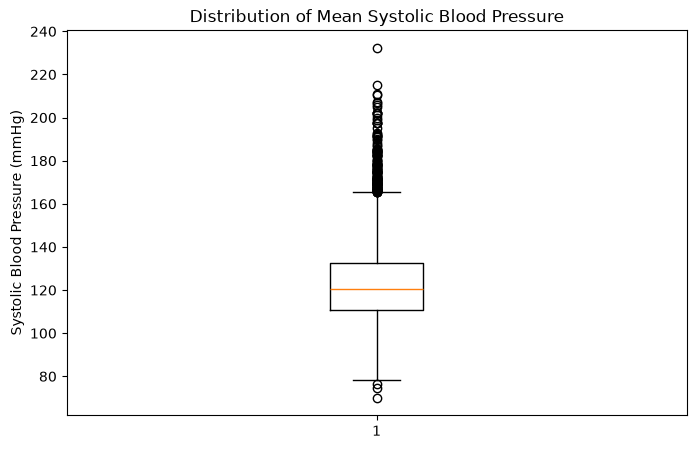

In [55]:
plt.figure(figsize=(8, 5))
plt.boxplot(analysis_data["Mean_Systolic"].dropna())
plt.ylabel("Systolic Blood Pressure (mmHg)")
plt.title("Distribution of Mean Systolic Blood Pressure")

plt.savefig(
    "../reports/figures/systolicbloodpressure_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

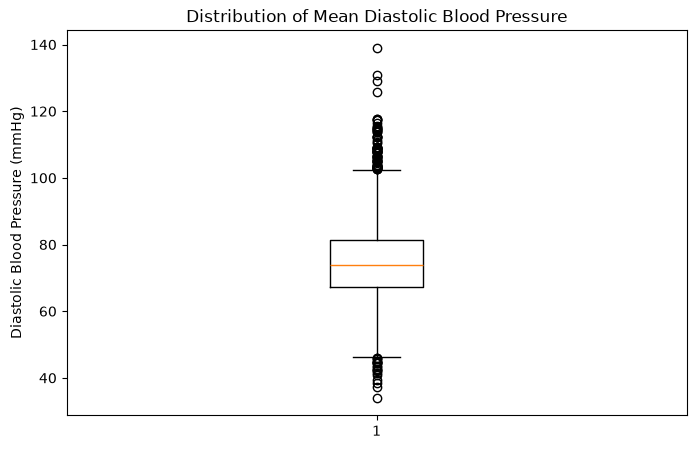

In [56]:
plt.figure(figsize=(8, 5))
plt.boxplot(analysis_data["Mean_Diastolic"].dropna())
plt.ylabel("Diastolic Blood Pressure (mmHg)")
plt.title("Distribution of Mean Diastolic Blood Pressure")

plt.savefig(
    "../reports/figures/diastolicbloodpressure_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [38]:
Q1_phq = analysis_data["PHQ9"].quantile(0.25)
Q3_phq = analysis_data["PHQ9"].quantile(0.75)

IQR_phq = Q3_phq - Q1_phq

lower_phq = Q1_phq - 1.5 * IQR_phq
upper_phq = Q3_phq + 1.5 * IQR_phq

phq_outliers = analysis_data[
    (analysis_data["PHQ9"] < lower_phq) |
    (analysis_data["PHQ9"] > upper_phq)
]

print("Q1:", Q1_phq)
print("Q3:", Q3_phq)
print("IQR:", IQR_phq)
print("Lower bound:", lower_phq)
print("Upper bound:", upper_phq)
print("Potential outliers:", len(phq_outliers))

Q1: 1.0
Q3: 6.0
IQR: 5.0
Lower bound: -6.5
Upper bound: 13.5
Potential outliers: 290


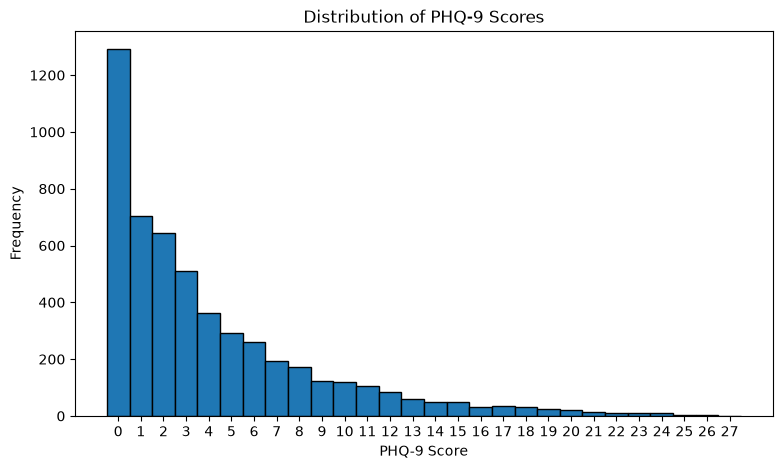

In [57]:
plt.figure(figsize=(9, 5))

plt.hist(
    analysis_data["PHQ9"].dropna(),
    bins=[i - 0.5 for i in range(29)],
    edgecolor="black"
)

plt.xlabel("PHQ-9 Score")
plt.ylabel("Frequency")
plt.title("Distribution of PHQ-9 Scores")
plt.xticks(range(28))

plt.savefig(
    "../reports/figures/phq9_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

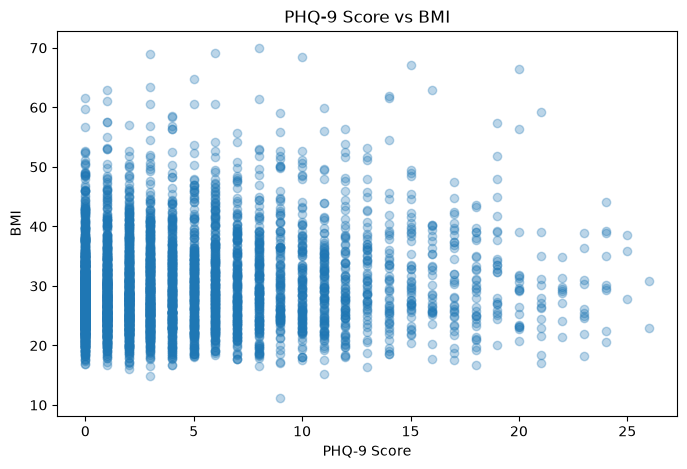

In [58]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_data["PHQ9"],
    analysis_data["BMXBMI"],
    alpha=0.3
)

plt.xlabel("PHQ-9 Score")
plt.ylabel("BMI")
plt.title("PHQ-9 Score vs BMI")

plt.savefig(
    "../reports/figures/phq9_bmi_scatterplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
correlation_data = analysis_data[
    ["PHQ9", "BMXBMI"]
].dropna()

correlation = correlation_data["PHQ9"].corr(
    correlation_data["BMXBMI"]
)

print("Number of observations:", len(correlation_data))
print("Pearson correlation:", correlation)

Number of observations: 5164
Pearson correlation: 0.10946149271851505


<div dir="rtl" style="text-align: right">
### بررسی ارتباط PHQ-9 و BMI

برای بررسی توصیفی ارتباط نمره PHQ-9 با شاخص BMI، از نمودار پراکندگی و ضریب همبستگی پیرسون استفاده شد.

تعداد مشاهدات دارای مقادیر معتبر برای هر دو متغیر 5164 نفر بود. ضریب همبستگی پیرسون برابر با 0.1095 به دست آمد که نشان‌دهنده یک ارتباط خطی مثبت اما ضعیف میان نمره PHQ-9 و BMI است.

بنابراین، در این نمونه شواهد بصری و توصیفی از یک ارتباط خطی قوی میان این دو متغیر مشاهده نشد. این نتیجه به معنای اثبات نبود رابطه یا وجود رابطه علّی نیست.
</div>

In [43]:
waist_data = analysis_data[
    ["PHQ9", "BMXWAIST"]
].dropna()

waist_correlation = waist_data["PHQ9"].corr(
    waist_data["BMXWAIST"]
)

print("Number of observations:", len(waist_data))
print("Pearson correlation:", waist_correlation)

Number of observations: 5056
Pearson correlation: 0.08022489185215179


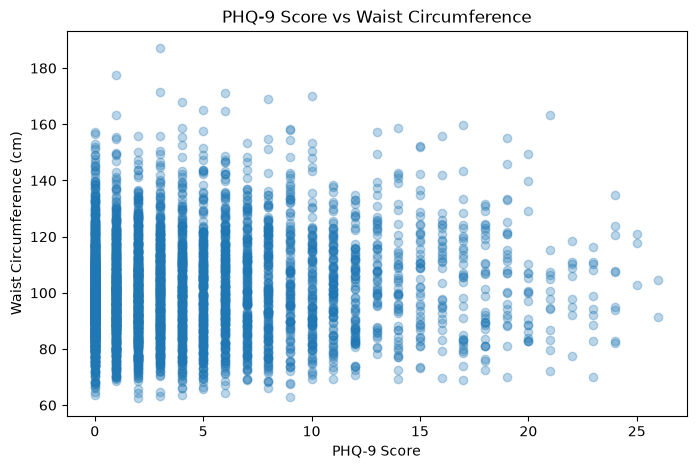

In [59]:
plt.figure(figsize=(8, 5))

plt.scatter(
    analysis_data["PHQ9"],
    analysis_data["BMXWAIST"],
    alpha=0.3
)

plt.xlabel("PHQ-9 Score")
plt.ylabel("Waist Circumference (cm)")
plt.title("PHQ-9 Score vs Waist Circumference")

plt.savefig(
    "../reports/figures/phq9_waist_scatterplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<div dir="rtl" style="text-align: right">
### بررسی ارتباط PHQ-9 و دور کمر

برای بررسی ارتباط توصیفی نمره PHQ-9 با دور کمر، از نمودار پراکندگی و ضریب همبستگی پیرسون استفاده شد.

تعداد مشاهدات دارای مقادیر معتبر برای هر دو متغیر 5056 نفر بود. ضریب همبستگی پیرسون برابر با 0.0802 به دست آمد که نشان‌دهنده ارتباط خطی مثبت بسیار ضعیف میان این دو متغیر است.

در مقایسه با BMI، ارتباط خطی مشاهده‌شده میان PHQ-9 و دور کمر ضعیف‌تر بود. این یافته به‌تنهایی نبود رابطه یا وجود رابطه علّی را اثبات نمی‌کند.
</div>

In [45]:
phq_categories = pd.cut(
    analysis_data["PHQ9"],
    bins=[-1, 4, 9, 14, 19, 27],
    labels=[
        "Minimal",
        "Mild",
        "Moderate",
        "Moderately Severe",
        "Severe"
    ]
)

phq_counts = phq_categories.value_counts(sort=False)

phq_percentages = phq_categories.value_counts(
    normalize=True,
    sort=False
) * 100

phq_summary = pd.DataFrame({
    "Frequency": phq_counts,
    "Percentage": phq_percentages
})

print(phq_summary)

                   Frequency  Percentage
PHQ9                                    
Minimal                 3513   67.428023
Mild                    1036   19.884837
Moderate                 420    8.061420
Moderately Severe        172    3.301344
Severe                    69    1.324376


In [46]:
phq_bmi_data = analysis_data[
    ["PHQ9", "BMXBMI"]
].dropna().copy()

phq_bmi_data["PHQ_Category"] = pd.cut(
    phq_bmi_data["PHQ9"],
    bins=[-1, 4, 9, 14, 19, 27],
    labels=[
        "Minimal",
        "Mild",
        "Moderate",
        "Moderately Severe",
        "Severe"
    ]
)

print(
    phq_bmi_data.groupby(
        "PHQ_Category",
        observed=False
    )["BMXBMI"].agg(["count", "mean", "median", "std"])
)

                   count       mean  median       std
PHQ_Category                                         
Minimal             3490  29.273209    28.1  6.634594
Mild                1028  30.817315    29.6  8.065804
Moderate             413  31.128087    29.6  8.567943
Moderately Severe    167  31.903593    30.3  8.580539
Severe                66  29.995455    29.3  8.927011


In [47]:
sex_bmi_summary = analysis_data.groupby("RIAGENDR")["BMXBMI"].agg(
    ["count", "mean", "median", "std"]
)

print(sex_bmi_summary)

          count       mean  median       std
RIAGENDR                                    
1.0        2680  29.281567    28.1  6.471328
2.0        3290  30.271368    28.7  7.982514


In [49]:
# Merge demographic and body measurement data
bmi_population = demo_adults.merge(
    bmx_adults,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

# Keep observations with valid BMI and MEC weight
obesity_data = bmi_population[
    bmi_population["BMXBMI"].notna() &
    bmi_population["WTMEC2YR"].notna()
].copy()

# Define obesity: BMI >= 30
obesity_data["Obese"] = (
    obesity_data["BMXBMI"] >= 30
).astype(int)

# Unweighted proportion
unweighted = obesity_data["Obese"].mean()

# Weighted proportion
weighted = np.average(
    obesity_data["Obese"],
    weights=obesity_data["WTMEC2YR"]
)

print("Sample size:", len(obesity_data))
print("Unweighted obesity proportion:", round(unweighted, 4))
print("Weighted obesity proportion:", round(weighted, 4))
print("Unweighted percentage:", round(unweighted * 100, 2), "%")
print("Weighted percentage:", round(weighted * 100, 2), "%")

Sample size: 5970
Unweighted obesity proportion: 0.4112
Weighted obesity proportion: 0.4027
Unweighted percentage: 41.12 %
Weighted percentage: 40.27 %


<div dir="rtl">
در میان ۵٬۹۷۰ شرکت‌کننده بزرگسال دارای اطلاعات معتبر BMI و وزن نمونه‌گیری، نسبت بدون وزن افراد دارای BMI برابر یا بیشتر از ۳۰، برابر با ۴۱٫۱۲ درصد بود. پس از اعمال وزن نمونه‌گیری MEC (WTMEC2YR)، این نسبت به ۴۰٫۲۷ درصد کاهش یافت. اختلاف ۰٫۸۵ واحد درصدی میان دو برآورد نشان می‌دهد که در نظر گرفتن طرح نمونه‌گیری می‌تواند بر برآورد شاخص‌های جمعیتی تأثیر بگذارد. این محاسبه یک برآورد نقطه‌ای وزن‌دار است و شامل خطای استاندارد یا فاصله اطمینان مبتنی بر طرح نمونه‌گیری پیچیده نیست.
</div>

In [50]:
categorical_vars = [
    "RIAGENDR",
    "RIDRETH3",
    "DMDEDUC2"
]

for var in categorical_vars:
    print("\nVariable:", var)
    print(analysis_data[var].value_counts(dropna=False))
    print(
        (analysis_data[var].value_counts(
            normalize=True,
            dropna=False
        ) * 100).round(2)
    )


Variable: RIAGENDR
RIAGENDR
2.0    3344
1.0    2720
Name: count, dtype: int64
RIAGENDR
2.0    55.15
1.0    44.85
Name: proportion, dtype: float64

Variable: RIDRETH3
RIDRETH3
3.0    3569
4.0     753
2.0     614
1.0     405
7.0     388
6.0     335
Name: count, dtype: int64
RIDRETH3
3.0    58.86
4.0    12.42
2.0    10.13
1.0     6.68
7.0     6.40
6.0     5.52
Name: proportion, dtype: float64

Variable: DMDEDUC2
DMDEDUC2
5.0    2143
4.0    1846
3.0    1297
2.0     482
1.0     292
9.0       4
Name: count, dtype: int64
DMDEDUC2
5.0    35.34
4.0    30.44
3.0    21.39
2.0     7.95
1.0     4.82
9.0     0.07
Name: proportion, dtype: float64
